# CardioIA - Fase 6: Sistema Integrado de Predição de Risco Cardíaco e Multiagentes
## Modelo Preditivo Supervisionado e Orquestração Multiagente (Mapika Decider & Handoffs)

**Objetivos desta atividade:**
1. Treinar um modelo de Machine Learning supervisionado para prever picos de risco cardíaco (`pico_risco`), utilizando a base sintética de pacientes.
2. Aplicar etapas de pré-processamento, separação entre treino/teste e avaliação detalhada (Acurácia, F1-Score, Matriz de Confusão, ROC-AUC).
3. Integrar o modelo a uma arquitetura multiagente com 4 agentes especializados:
   - **Agente Orquestrador:** Coordena o fluxo e recebe os dados de entrada.
   - **Agente Analista de Risco:** Executa o modelo preditivo e gera o score de risco.
   - **Agente Especialista em Protocolos:** Cruza os achados com a base de protocolos simulados utilizando o **Mapika Decider 4B**.
   - **Agente Planejador de Resposta:** Sintetiza as recomendações clínicas e emite a resposta estruturada.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Adiciona o diretório raiz ao sys.path para garantir imports
base_dir = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(base_dir) not in sys.path:
    sys.path.insert(0, str(base_dir))

# Configuração de visualização
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Importações dos módulos do CardioIA
from data.generate_dataset import generate_synthetic_data
from src.ml.train import split_data, train_and_compare_models, FEATURE_COLUMNS, TARGET_COLUMN
from src.ml.predictor import CardiacRiskPredictor
from src.agents.runner import MultiAgentPipelineRunner

print('Módulos do CardioIA carregados com sucesso!')


Módulos do CardioIA carregados com sucesso!


## 1. Geração e Exploração da Base de Dados Sintética Realista
Conforme especificado na atividade, geramos 5.000 amostras simuladas preservando privacidade e variabilidade clínica.


In [2]:
df = generate_synthetic_data(n=5000, random_seed=42)
print(f'Dimensões do dataset: {df.shape}')
df.head()


Dimensões do dataset: (5000, 12)


,idade_media,carga_sistema,tempo_espera,fc_media,spo2_media,pa_sistolica,temperatura,densidade_eventos,eventos_24h,disponibilidade_recursos,risk_score,pico_risco
0,60.960570,41.776561,26.230658,111.709579,92.960100,131.711117,25.449200,1,2,35.486591,2,1
1,53.340828,43.295432,34.071848,112.443439,96.509986,81.160294,18.040015,4,1,82.232538,1,0
2,62.772262,62.249852,39.355188,76.369939,94.709752,163.880966,19.905007,6,0,88.160917,0,0
3,73.276358,50.039590,66.015486,88.797755,93.714735,131.224152,28.616685,2,2,89.771810,1,0
4,52.190160,47.322409,21.741220,63.560997,95.784214,138.439755,33.384496,4,0,62.786630,0,0


/tmp/ipykernel_37634/1554463570.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='pico_risco', data=df, palette='Blues_r')


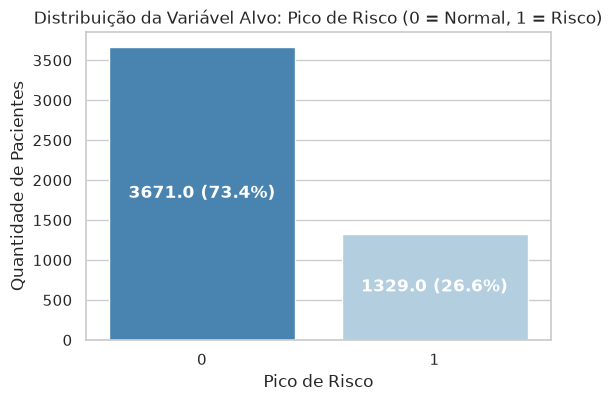

In [3]:
# Distribuição da variável alvo (pico_risco)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='pico_risco', data=df, palette='Blues_r')
plt.title('Distribuição da Variável Alvo: Pico de Risco (0 = Normal, 1 = Risco)')
plt.xlabel('Pico de Risco')
plt.ylabel('Quantidade de Pacientes')
for p in ax.patches:
    ax.annotate(f'{p.get_height()} ({p.get_height()/len(df)*100:.1f}%)', 
                (p.get_x() + p.get_width() / 2., p.get_height() / 2), 
                ha='center', va='center', color='white', fontweight='bold')
plt.show()


## 2. Treinamento e Comparação de Modelos Supervisionados
Separamos 80% dos dados para treino e 20% para teste com estratificação da classe alvo.
Comparamos cinco algoritmos supervisionados clássicos:
1. **Random Forest** (Ensemble de árvores bagging)
2. **Gradient Boosting** (Ensemble sequencial boosting)
3. **SVM - Support Vector Machine** (Margem máxima com calibração de probabilidade)
4. **KNN - K-Nearest Neighbors** (Baseado em vizinhança euclidiana e voto majoritário)
5. **Logistic Regression** (Linear probabilístico baseline)


In [4]:
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)
print(f'Tamanho do conjunto de treino: {X_train.shape[0]} instâncias')
print(f'Tamanho do conjunto de teste:  {X_test.shape[0]} instâncias')

results = train_and_compare_models(X_train, y_train, X_test, y_test)
best_model_name = results['best_model_name']
best_pipe = results['best_pipeline']


Tamanho do conjunto de treino: 4000 instâncias
Tamanho do conjunto de teste:  1000 instâncias

=== BENCHMARK DE MODELOS DE CLASSIFICAÇÃO ===


[RandomForest] Acurácia: 0.9990 | F1: 0.9981 | ROC-AUC: 1.0000 (CV: 1.0000 ± 0.0000)


[GradientBoosting] Acurácia: 0.9980 | F1: 0.9962 | ROC-AUC: 0.9999 (CV: 0.9999 ± 0.0002)
[LogisticRegression] Acurácia: 0.8160 | F1: 0.6151 | ROC-AUC: 0.8715 (CV: 0.8864 ± 0.0106)


[KNN] Acurácia: 0.8370 | F1: 0.6091 | ROC-AUC: 0.8751 (CV: 0.8864 ± 0.0067)


[SVM] Acurácia: 0.8770 | F1: 0.7555 | ROC-AUC: 0.9488 (CV: 0.9507 ± 0.0043)

>> Campeão Selecionado: RandomForest (ROC-AUC: 1.0000)


## 3. Avaliação Detalhada do Modelo Campeão
Avaliamos a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score no conjunto de teste.


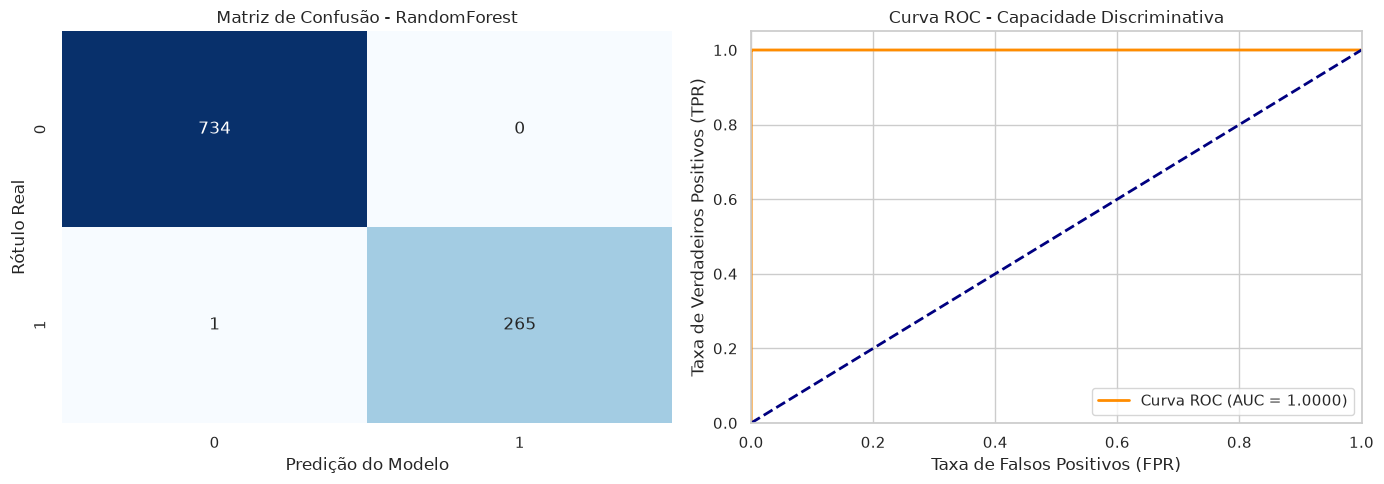

Relatório de Classificação:
              precision    recall  f1-score   support

           0     0.9986    1.0000    0.9993       734
           1     1.0000    0.9962    0.9981       266

    accuracy                         0.9990      1000
   macro avg     0.9993    0.9981    0.9987      1000
weighted avg     0.9990    0.9990    0.9990      1000



In [5]:
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report

y_pred = best_pipe.predict(X_test)
y_proba = best_pipe.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Matriz de Confusão
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Matriz de Confusão - {best_model_name}')
axes[0].set_xlabel('Predição do Modelo')
axes[0].set_ylabel('Rótulo Real')

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('Taxa de Falsos Positivos (FPR)')
axes[1].set_ylabel('Taxa de Verdadeiros Positivos (TPR)')
axes[1].set_title('Curva ROC - Capacidade Discriminativa')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

print('Relatório de Classificação:\n' + classification_report(y_test, y_pred, digits=4))


## 4. Integração com o Pipeline Multiagente (Hub-and-Spoke Centralizado)
A arquitetura é centralizada no **Agente Orquestrador**, que avalia a saída de cada etapa e decide os handoffs:
1. **Orquestrador** analisa admissão e transfere para o **Analista de Risco**
2. **Analista de Risco** calcula risco (ML) e devolve laudo ao **Orquestrador**
3. **Orquestrador** avalia laudo e transfere para o **Especialista em Protocolos** (Mapika Decider 4B)
4. **Especialista em Protocolos** extrai protocolos e devolve evidências ao **Orquestrador**
5. **Orquestrador** audita o dossiê completo e despacha para o **Planejador de Resposta**


In [ ]:
novo_caso = pd.DataFrame([{
    'idade_media': 62,
    'carga_sistema': 92,
    'tempo_espera': 75,
    'fc_media': 118,
    'spo2_media': 89,
    'pa_sistolica': 100,
    'temperatura': 37.5,
    'densidade_eventos': 7,
    'eventos_24h': 5,
    'disponibilidade recursos': 25
}])

runner = MultiAgentPipelineRunner()
final_response = runner.run(novo_caso)

print('=== HISTÓRICO DE MENSAGENS E HANDOFFS ENTRE AGENTES ===')
for msg in runner.history:
    print(f'[{msg.message_type.upper()}] {msg.sender} -> {msg.recipient}')
    print(f'  {msg.content}\n')


[Mapika Decider] Pacote decider inicializado com sucesso para decider-4b.
=== HISTÓRICO DE MENSAGENS E HANDOFFS ENTRE AGENTES ===
[INPUT] Usuário / Sistema Hospitalar -> Agente Orquestrador
  Novo paciente recebido para triagem: SpO2=89.0%, FC=118.0 bpm, Carga=92.0%

[DECISION] Agente Orquestrador -> Agente Orquestrador
  Orquestrador avalia dados clínicos iniciais e decide acionar o Agente Analista de Risco para cálculo do score preditivo de ML.

[HANDOFF] Agente Orquestrador -> Agente Analista de Risco
  Orquestrador despacha paciente para análise preditiva supervisionada.

[TOOL_CALL] Agente Analista de Risco -> Tool: predict_cardiac_risk
  Invocando modelo preditivo supervisionado (Random Forest Pipeline / Joblib)

[TOOL_RESULT] Tool: predict_cardiac_risk -> Agente Analista de Risco
  Probabilidade calculada: 1.00 (ALTO RISCO), Risk Score Base=6

[HANDOFF] Agente Analista de Risco -> Agente Orquestrador
  Laudo concluído: Risco=1.00 (ALTO RISCO). Devolvendo controle ao Orquestrador

### Saída Final Estruturada do Sistema


In [7]:
print(final_response.format_task_output())


RISCO PREVISTO: 1.00

PROTOCOLOS SUGERIDOS:
- Se SPO2 < 88% → iniciar suporte respiratório imediato
- Se carga do sistema > 85% → abrir unidades temporárias
- Se disponibilidade_recursos < 30% → redistribuir insumos
- Se densidade_eventos > 6 → ativar plano de contingência
- Se risco sistêmico alto → ativar estado de emergência
